# Clothing Category Recognition: Phase 1 master notebook

**Team:** Nakul, Sudeshhna, Puneet, Samarth and Neelanshu.

This executed notebook examines **pixels versus HOG with four classical classifiers**.
It reads saved experiment evidence and independently checks the reported metrics.
It does not retrain models or silently repeat final test selection when opened.

**AI assistance:** Code and initial analysis were prepared with Codex at Nakul's request.
Each student still needs to review the work, record real contributions and prepare for the individual viva.
The CNN and any hybrid approach belong to Phase 2.

## Setup

Install the project with `python -m pip install -e '.[dev]'` from the repository root.
Use its virtual environment as your notebook kernel. The original data files are downloaded
from the official source if missing and checked against published checksums.
Saved test evidence must already exist before running this read-only notebook.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from skimage.feature import hog
from clothing_ml.utils import ROOT, read_json, sha256
from clothing_ml.data import CLASS_NAMES, load_official
from clothing_ml.features import HOG_SETTINGS, make_features, normalized_images
from clothing_ml.evaluate import label_metrics, validate_predictions
from clothing_ml.experiments import validate_manifest

PROFILE = "full"
RESULTS = ROOT / "results" / PROFILE
manifest = read_json(RESULTS / "freeze.json")
validate_manifest(manifest)
validation = pd.read_csv(RESULTS / "validation_summary.csv")
test = pd.read_csv(RESULTS / "test_summary.csv")
selected_id = manifest["selected_run_id"]
selected = test.set_index("run_id").loc[selected_id]
assert test.train_n.nunique() == 1 and len(test) == 8
plt.rcParams.update({"font.size": 10, "figure.figsize": (10, 4),
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.precision", 4)
print("Profile:", PROFILE, "| Fit rows per model:", int(test.train_n.iloc[0]))
print("Recorded Python/packages:", manifest["environment"]["python"], manifest["environment"]["packages"])

Profile: full | Fit rows per model: 48000
Recorded Python/packages: 3.12.14 {'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scikit-image': '0.26.0', 'matplotlib': '3.11.2', 'joblib': '1.6.0', 'threadpoolctl': '3.7.0'}


## tl;dr

In [2]:
display(Markdown(
    f"The model selected using **validation only** was **{selected.feature} + {selected.model.upper()}**. "
    f"On the official 10,000-image test partition, it achieved **{selected.accuracy:.2%} accuracy** "
    f"and **{selected.macro_f1:.4f} macro F1**. All eight final rows used "
    f"**{int(selected.train_n):,} identical fit examples** and the same validation/test partitions. "
    "The detailed comparison below includes weaker categories and inference costs; "
    "it does not establish performance on arbitrary catalogue photos or a future CNN."))

The model selected using **validation only** was **hog + SVM**. On the official 10,000-image test partition, it achieved **90.91% accuracy** and **0.9090 macro F1**. All eight final rows used **48,000 identical fit examples** and the same validation/test partitions. The detailed comparison below includes weaker categories and inference costs; it does not establish performance on arbitrary catalogue photos or a future CNN.

## Context & Methods

The question is whether an explicit local-edge description changes classification
compared with raw intensities, and whether that effect depends on the classifier.

1. Official training data -> fixed stratified 48,000/12,000 fit/validation split, seed 42.
2. Development: two candidates per row on a saved 12,000-image subset of the fit pool;
   unchanged validation set. This is a modest search, not exhaustive optimization.
3. Final fitting: the eight development-selected configurations are fitted afresh on all
   48,000 fit images, including each learned scaler. Validation labels are never fitted.
4. Choose the overall final model using final validation macro F1 (then declared tie-breaks).
5. Freeze artifact hashes, then evaluate all eight on the official 10,000-image test partition.

### Key Assumptions

- The one fixed split is representative enough for this course comparison; no repeated-seed
  or cross-validation uncertainty analysis is claimed.
- Pixels and HOG are fixed transforms; learned standardization stays inside Pipelines.
- Preprocessing is intentionally model-specific. Representation comparisons are comparisons
  of the declared pipelines, not a pure HOG ablation under every possible scaler.
- Test error panels describe frozen models and do not authorize further test-driven tuning.
- Full details and primary sources: `docs/protocol.md`, `docs/literature_review.md`,
  `report/references.bib`. Original dataset: https://github.com/zalandoresearch/fashion-mnist.

## Data

### 1. Verify the training audit and original IDs

An original image ID stays attached to its true label. The `source_split` disambiguates
the same numeric ID in official training versus official test. The audit below concerns
official training only; it did not inspect test content during development.

In [3]:
train_images, train_labels = load_official("train")
audit = read_json(ROOT / "data/training_audit.json")
with np.load(ROOT / "data/full_indices.npz") as split:
    fit_ids, val_ids = split["train_idx"], split["val_idx"]
assert len(fit_ids) == 48000 and len(val_ids) == 12000
assert not np.intersect1d(fit_ids, val_ids).size
assert np.array_equal(np.sort(np.r_[fit_ids, val_ids]), np.arange(60000))
display(pd.DataFrame({"check": ["raw shape", "dtype", "pixel range", "finite", "all-zero images",
                               "exact duplicate groups", "conflicting duplicate groups", "fit/validation duplicate groups"],
                      "observed": [str(audit["shape"]), audit["dtype"],
                                   f"{audit['pixel_min']}..{audit['pixel_max']}", str(audit["finite"]),
                                   str(audit["all_zero_images"]), str(audit["exact_duplicate_groups"]),
                                   str(audit["conflicting_label_duplicate_groups"]), str(audit["fit_val_duplicate_groups"])]}))

,check,observed
0,raw shape,"[60000, 28, 28]"
1,dtype,uint8
2,pixel range,0..255
3,finite,True
4,all-zero images,0
5,exact duplicate groups,0
6,conflicting duplicate groups,0
7,fit/validation duplicate groups,0


The exact-image hash audit does not detect all near-duplicates or prove every semantic label
is correct. No examples were removed or relabeled. Original sample membership is saved in `.npz` files.

### 2. Inspect seeded fit examples

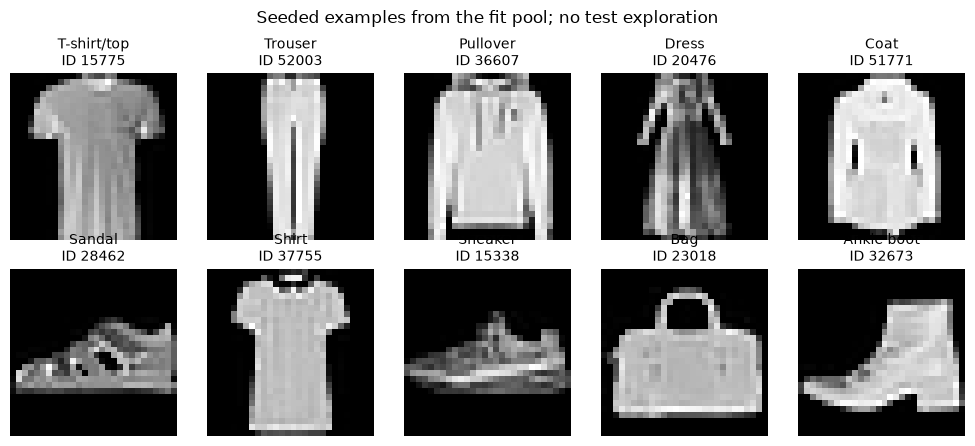

In [4]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for category, ax in enumerate(axes.flat):
    image_id = int(rng.choice(fit_ids[train_labels[fit_ids] == category]))
    ax.imshow(train_images[image_id], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[category]}\nID {image_id}", fontsize=10)
    ax.axis("off")
fig.suptitle("Seeded examples from the fit pool; no test exploration")
fig.tight_layout()
plt.show()

### 3. Check class balance

,category,fit_pool,validation
0,T-shirt/top,4800,1200
1,Trouser,4800,1200
2,Pullover,4800,1200
3,Dress,4800,1200
4,Coat,4800,1200
5,Sandal,4800,1200
6,Shirt,4800,1200
7,Sneaker,4800,1200
8,Bag,4800,1200
9,Ankle boot,4800,1200


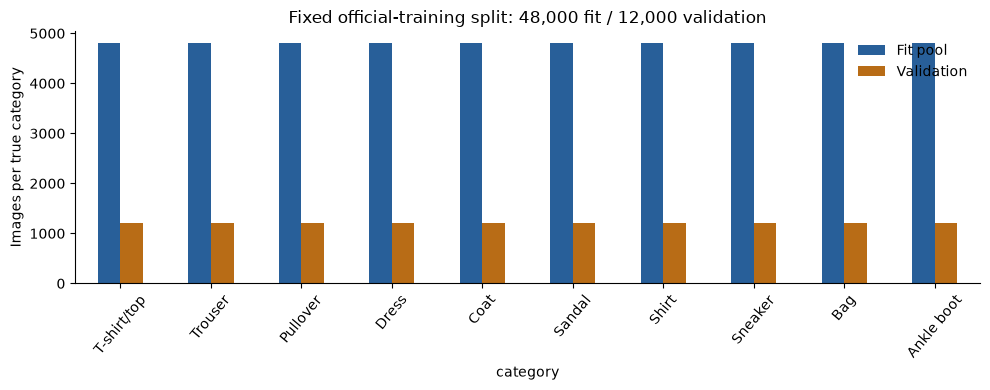

In [5]:
counts = pd.DataFrame({"category": CLASS_NAMES,
                       "fit_pool": np.bincount(train_labels[fit_ids], minlength=10),
                       "validation": np.bincount(train_labels[val_ids], minlength=10)})
display(counts)
ax = counts.set_index("category").plot.bar(color=["#285F99", "#B86C16"], rot=50, figsize=(10, 4))
ax.set_ylabel("Images per true category")
ax.set_title("Fixed official-training split: 48,000 fit / 12,000 validation")
ax.legend(["Fit pool", "Validation"], frameon=False)
plt.tight_layout()
plt.show()

## Results

### 4. Inspect the two representations

Flattening preserves intensity values and their recoverable ordering but supplies no built-in
local-neighborhood bias. HOG summarizes local gradients using a fixed rule. For this setup:
7 cells per axis -> 6 overlapping blocks per axis -> 6 x 6 x 2 x 2 x 9 = **1,296** values.
HOG is not dimensionality reduction here.

Pixel shape: (1, 784) | HOG shape: (1, 1296)


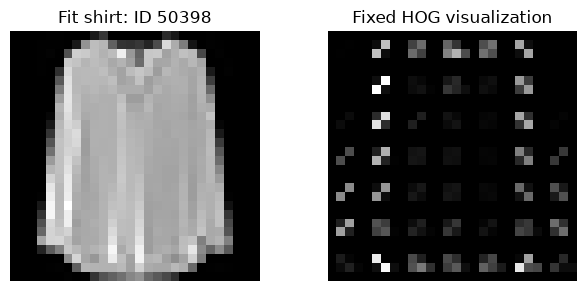

In [6]:
image_id = int(fit_ids[train_labels[fit_ids] == 6][0])
raw = train_images[image_id:image_id + 1]
pixels, hog_vector = make_features(raw, "pixels"), make_features(raw, "hog")
print("Pixel shape:", pixels.shape, "| HOG shape:", hog_vector.shape)
_, visualization = hog(normalized_images(raw)[0], visualize=True, **HOG_SETTINGS)
fig, axes = plt.subplots(1, 2, figsize=(6.5, 3))
axes[0].imshow(raw[0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Fit shirt: ID {image_id}")
axes[1].imshow(visualization, cmap="gray")
axes[1].set_title("Fixed HOG visualization")
for ax in axes: ax.axis("off")
fig.tight_layout()
plt.show()

### 5. Connect theory to the model factories

| Model | Decision rule | Development setting | Scaling |
|---|---|---|---|
| Logistic Regression | Learned linear class scores; softmax classification | C=0.1 or 1 | StandardScaler |
| kNN | Distance-weighted vote among stored neighbors | k=3 or 5 | Pixel passthrough; HOG standardized |
| Random Forest | Combine randomized tree predictions | depth=20 or unrestricted; 200 trees | Passthrough |
| RBF SVM | Nonlinear margin-based decisions | C=1 or 10; gamma='scale' | StandardScaler |

Smaller LR C means stronger regularization. kNN can fit quickly while retaining expensive
prediction/storage costs. RF samples training examples/features. SVC trains pairwise classifiers
for the ten classes. See the actual code in `src/clothing_ml/models.py`.

In [7]:
development = pd.read_csv(ROOT / "results/budget/validation_candidates.csv")
display(development[["feature", "model", "train_n", "macro_f1", "accuracy", "fit_seconds", "converged"]])
display(Markdown("**Development only:** 12,000 fit examples per candidate. These scores are not mixed with full-profile or test results."))
display(pd.DataFrame([{"feature": r["feature"], "model": r["model"], "selected_parameters": r["parameters"]}
                      for r in manifest["finalists"]]))

,feature,model,train_n,macro_f1,accuracy,fit_seconds,converged
0,pixels,lr,12000,0.8375,0.8376,1.5630,True
1,pixels,lr,12000,0.8083,0.8079,1.6267,True
2,pixels,knn,12000,0.8320,0.8316,0.0016,True
3,pixels,knn,12000,0.8346,0.8347,0.0027,True
4,pixels,rf,12000,0.8623,0.8642,11.4020,True
5,pixels,rf,12000,0.8646,0.8663,11.4631,True
6,pixels,svm,12000,0.8696,0.8709,4.6939,True
7,pixels,svm,12000,0.8800,0.8804,5.0579,True
8,hog,lr,12000,0.8540,0.8538,0.9687,True
9,hog,lr,12000,0.8385,0.8382,1.1800,True


**Development only:** 12,000 fit examples per candidate. These scores are not mixed with full-profile or test results.

,feature,model,selected_parameters
0,pixels,lr,{'C': 0.1}
1,pixels,knn,{'n_neighbors': 5}
2,pixels,rf,{'max_depth': None}
3,pixels,svm,{'C': 10.0}
4,hog,lr,{'C': 0.1}
5,hog,knn,{'n_neighbors': 5}
6,hog,rf,{'max_depth': None}
7,hog,svm,{'C': 10.0}


### 6. Read the full-profile validation decision

In [8]:
display(validation.sort_values("macro_f1", ascending=False))
rule_order = sorted(manifest["finalists"], key=lambda r: (-r["macro_f1"], -r["accuracy"], r["validation_predict_seconds"], r["run_id"]))
assert rule_order[0]["run_id"] == selected_id
assert manifest["test_used_for_selection"] is False
display(Markdown(f"**Frozen overall model:** `{selected_id}`. This identifier was saved before loading test content."))
dummy = read_json(ROOT / "results/full/dummy_validation.json")
print("Most-frequent dummy validation accuracy/F1:", dummy["accuracy"], dummy["macro_f1"])

,run_id,feature,model,train_n,feature_dim,accuracy,macro_f1,fit_seconds,serialized_bytes
7,full_hog_svm_3fd9d87a,hog,svm,48000,1296,0.9116,0.9114,125.4202,92083815
3,full_pixels_svm_3fd9d87a,pixels,svm,48000,784,0.9072,0.9068,100.6949,41251876
4,full_hog_lr_580addbb,hog,lr,48000,1296,0.8832,0.8834,4.2054,80201
2,full_pixels_rf_297afe2b,pixels,rf,48000,784,0.8838,0.8828,57.5396,36713164
6,full_hog_rf_297afe2b,hog,rf,48000,1296,0.8762,0.8752,104.8872,42190315
5,full_hog_knn_65305bf5,hog,knn,48000,1296,0.8756,0.8749,0.1807,154424671
0,full_pixels_lr_580addbb,pixels,lr,48000,784,0.8596,0.8590,6.9205,49125
1,full_pixels_knn_65305bf5,pixels,knn,48000,784,0.8584,0.8585,0.0067,32614887


**Frozen overall model:** `full_hog_svm_3fd9d87a`. This identifier was saved before loading test content.

Most-frequent dummy validation accuracy/F1: 0.1 0.01818181818181818


### 7. Independently regenerate test metrics from predictions

Accuracy is total correct / N. Per-class recall is TP/(TP+FN). Macro F1 averages ten
separately calculated class F1 values equally; it is not F1 of averaged precision/recall.
Missing/duplicate sample IDs or incorrect true labels cause validation to fail.

In [9]:
test_images, test_labels = load_official("test")
test_ids = np.arange(len(test_labels))
predictions = {}
regenerated = []
for row in manifest["finalists"]:
    run_id = row["run_id"]
    frame = pd.read_csv(RESULTS / "predictions" / f"{run_id}_test.csv.gz")
    frame = validate_predictions(frame, test_ids, test_labels, "test", run_id)
    metrics = label_metrics(frame.y_true, frame.y_pred)
    recorded = test.set_index("run_id").loc[run_id]
    assert np.isclose(metrics["accuracy"], recorded.accuracy, atol=1e-12)
    assert np.isclose(metrics["macro_f1"], recorded.macro_f1, atol=1e-12)
    predictions[(row["feature"], row["model"])] = frame.y_pred.to_numpy()
    regenerated.append({"feature": row["feature"], "model": row["model"],
                        "accuracy": metrics["accuracy"], "macro_f1": metrics["macro_f1"]})
display(pd.DataFrame(regenerated))
print("All eight test rows independently regenerated and ID-checked.")

,feature,model,accuracy,macro_f1
0,pixels,lr,0.8401,0.8394
1,pixels,knn,0.8504,0.8505
2,pixels,rf,0.8767,0.8753
3,pixels,svm,0.8928,0.8924
4,hog,lr,0.8760,0.8757
5,hog,knn,0.8734,0.8730
6,hog,rf,0.8729,0.8718
7,hog,svm,0.9091,0.9090


All eight test rows independently regenerated and ID-checked.


### 8. Compare representations within each classifier

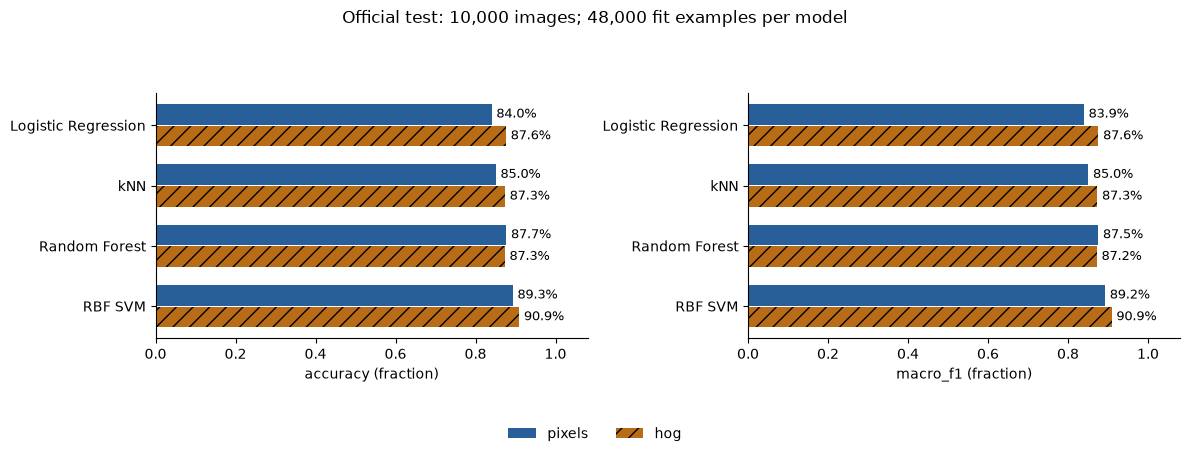

In [10]:
models = ["lr", "knn", "rf", "svm"]
names = ["Logistic Regression", "kNN", "Random Forest", "RBF SVM"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    for feature, offset, color in [("pixels", -.18, "#285F99"), ("hog", .18, "#B86C16")]:
        values = [test[(test.feature == feature) & (test.model == m)][metric].iloc[0] for m in models]
        bars = ax.barh(np.arange(4) + offset, values, height=.34, color=color, label=feature,
                       hatch="//" if feature == "hog" else None)
        for bar, value in zip(bars, values):
            ax.text(value + .012, bar.get_y() + bar.get_height()/2, f"{value:.1%}", va="center", fontsize=9)
    ax.set_yticks(range(4), names)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.08)
    ax.set_xlabel(metric + " (fraction)")
fig.suptitle(f"Official test: 10,000 images; {int(selected.train_n):,} fit examples per model")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, .12, 1, .90))
plt.show()

In [11]:
deltas = []
for model in models:
    subset = test[test.model == model].set_index("feature")
    deltas.append({"model": model,
                   "accuracy_change_pp": 100*(subset.loc["hog", "accuracy"]-subset.loc["pixels", "accuracy"]),
                   "macro_f1_change_pp": 100*(subset.loc["hog", "macro_f1"]-subset.loc["pixels", "macro_f1"])})
display(pd.DataFrame(deltas))
display(Markdown("Positive values favor HOG. These are observed differences on one split, not statistical-significance or causal claims. The declared scaler choices are part of the pipelines."))

,model,accuracy_change_pp,macro_f1_change_pp
0,lr,3.59,3.6300
1,knn,2.30,2.2571
2,rf,-0.38,-0.3535
3,svm,1.63,1.6518


Positive values favor HOG. These are observed differences on one split, not statistical-significance or causal claims. The declared scaler choices are part of the pipelines.

### 9. Inspect every category's recall

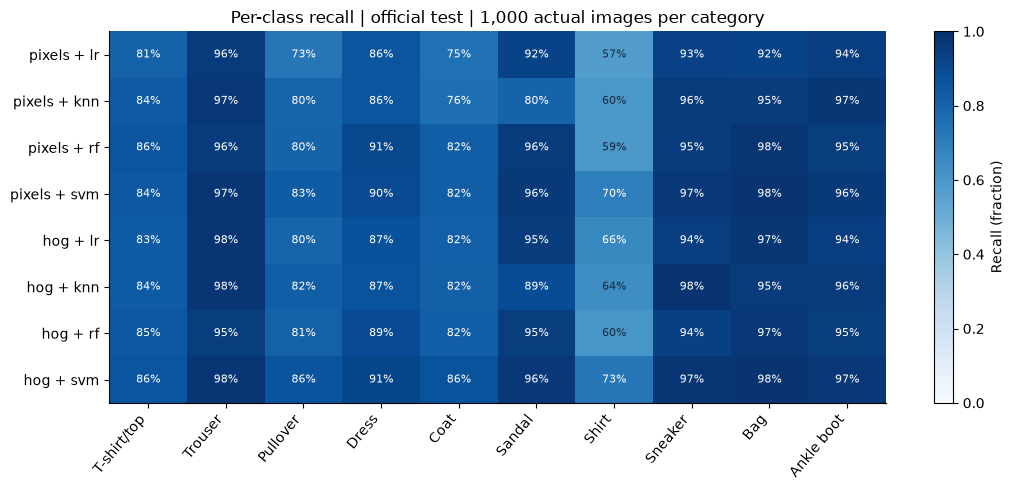

,category,support,recall
146,Shirt,1000,0.733
140,T-shirt/top,1000,0.857
142,Pullover,1000,0.862
144,Coat,1000,0.864
143,Dress,1000,0.912
145,Sandal,1000,0.965
149,Ankle boot,1000,0.966
147,Sneaker,1000,0.973
141,Trouser,1000,0.976
148,Bag,1000,0.983


In [12]:
recall = pd.read_csv(RESULTS / "per_class_recall.csv")
order = [r["run_id"] for r in manifest["finalists"]]
recall_matrix = recall[recall.stage == "test"].pivot(index="run_id", columns="label", values="recall").loc[order, range(10)]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(recall_matrix.to_numpy(), vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks(range(10), CLASS_NAMES, rotation=50, ha="right")
ax.set_yticks(range(8), [f"{r['feature']} + {r['model']}" for r in manifest["finalists"]])
for i in range(8):
    for j in range(10):
        value = recall_matrix.iloc[i,j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=8,
                color="white" if value > .65 else "#17293D")
ax.set_title("Per-class recall | official test | 1,000 actual images per category")
fig.colorbar(im, ax=ax, label="Recall (fraction)")
fig.tight_layout()
plt.show()
selected_recalls = recall[(recall.stage == "test") & (recall.run_id == selected_id)]
display(selected_recalls[["category", "support", "recall"]].sort_values("recall"))

### 10. Explain the validation-selected model's confusion

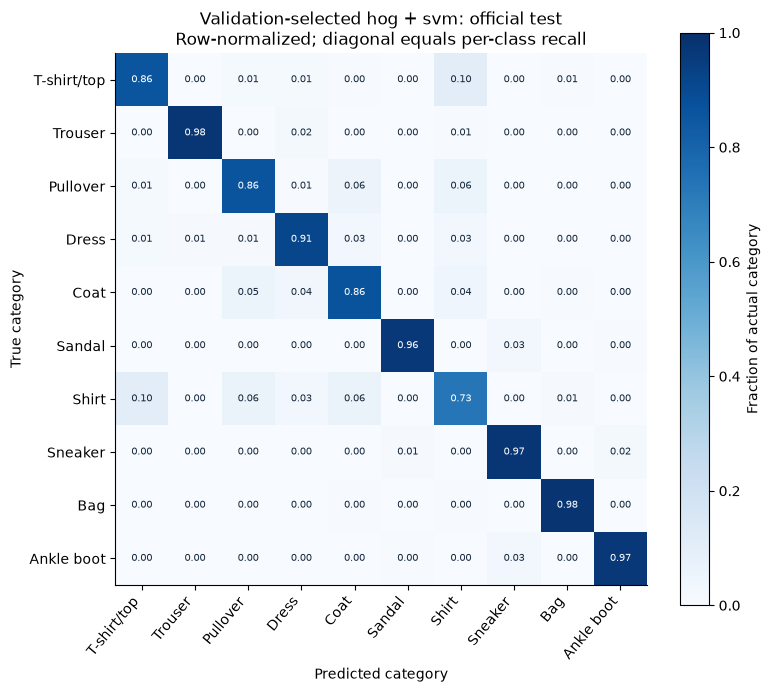

,true_category,predicted_category,errors
0,T-shirt/top,Shirt,104
1,Shirt,T-shirt/top,103
2,Shirt,Coat,64
3,Shirt,Pullover,63
4,Pullover,Shirt,59


In [13]:
selected_predictions = predictions[(selected.feature, selected.model)]
selected_metrics = label_metrics(test_labels, selected_predictions)
cm = np.asarray(selected_metrics["confusion"])
row_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(row_norm, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(10), CLASS_NAMES, rotation=50, ha="right")
ax.set_yticks(range(10), CLASS_NAMES)
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{row_norm[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if row_norm[i,j] > .65 else "#17293D")
ax.set_title(f"Validation-selected {selected.feature} + {selected.model}: official test\nRow-normalized; diagonal equals per-class recall")
fig.colorbar(im, ax=ax, label="Fraction of actual category")
fig.tight_layout()
plt.show()
np.fill_diagonal(cm, 0)
top_cells = np.argsort(cm.ravel())[::-1][:5]
display(pd.DataFrame([{"true_category": CLASS_NAMES[k//10], "predicted_category": CLASS_NAMES[k%10],
                       "errors": int(cm.ravel()[k])} for k in top_cells]))

### 11. See paired errors instead of selecting only favorable pictures

The following panel compares both representations **within SVM**, using the smallest
original IDs from each outcome group. The rule is symmetric and deterministic. All
four classifiers' complete example panels and selected IDs are saved under `figures/full/`
and `results/full/error_example_ids.csv`. Visual observations suggest possible explanations;
they do not prove a mechanism or establish that ambiguous labels are wrong.

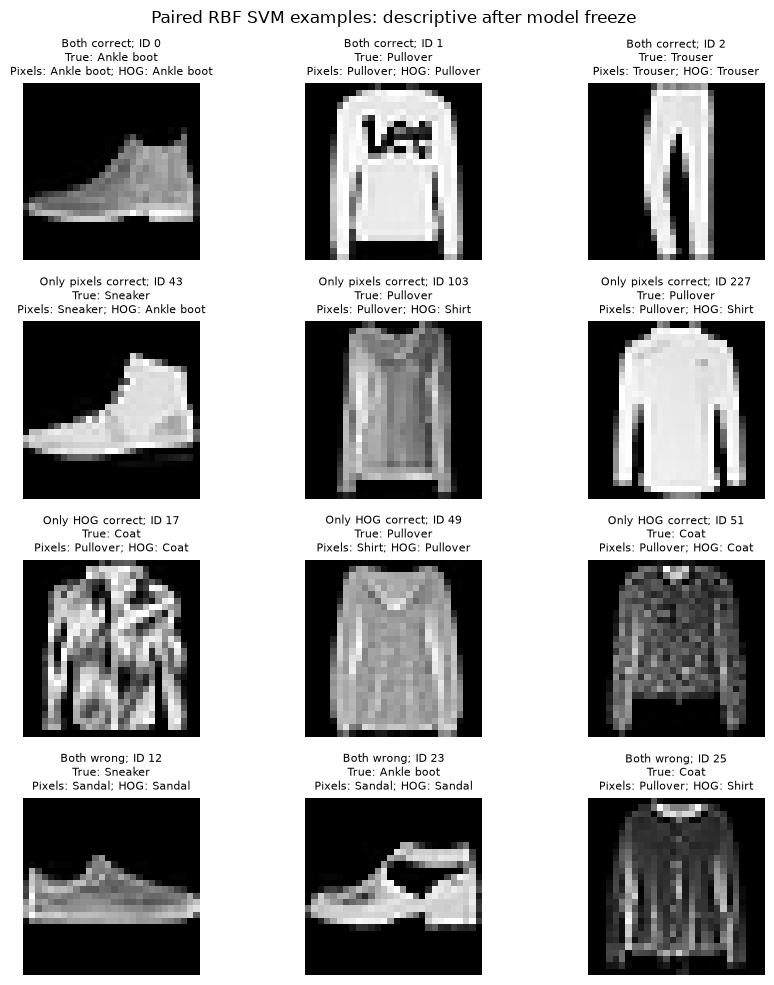

,group,test_images
0,Both correct,8534
1,Only pixels correct,394
2,Only HOG correct,557
3,Both wrong,515


In [14]:
pixel_pred, hog_pred = predictions[("pixels", "svm")], predictions[("hog", "svm")]
pc, hc = pixel_pred == test_labels, hog_pred == test_labels
groups = [("Both correct", pc & hc), ("Only pixels correct", pc & ~hc),
           ("Only HOG correct", ~pc & hc), ("Both wrong", ~pc & ~hc)]
fig, axes = plt.subplots(4, 3, figsize=(9, 10))
for i, (label, mask) in enumerate(groups):
    chosen = test_ids[mask][:3]
    for j, ax in enumerate(axes[i]):
        ax.axis("off")
        if j < len(chosen):
            k = chosen[j]
            ax.imshow(test_images[k], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"{label}; ID {k}\nTrue: {CLASS_NAMES[test_labels[k]]}\nPixels: {CLASS_NAMES[pixel_pred[k]]}; HOG: {CLASS_NAMES[hog_pred[k]]}", fontsize=8)
fig.suptitle("Paired RBF SVM examples: descriptive after model freeze")
fig.tight_layout()
plt.show()
display(pd.DataFrame({"group": [g[0] for g in groups], "test_images": [int(g[1].sum()) for g in groups]}))

### 12. Read fit time, inference time and complexity honestly

The benchmark starts with loaded models and in-memory data. End-to-end includes normalization,
fixed feature extraction, scaler and classification; Pipeline-only begins at cached fixed features.
Both exclude disk/model-loading time. Five repeats of 1,024 fixed test images in batches of 128
produce an **amortized batch cost**, not single-request latency.

Counts below describe different structures. kNN stored scalars, RF nodes and SVM support-vector
storage are not interchangeable with neural-network-style trainable weights.

In [15]:
display(test[["feature", "model", "fit_seconds", "predict_ms_per_image", "end_to_end_ms_per_image", "serialized_bytes"]])
complexities = read_json(RESULTS / "complexity.json")
display(pd.DataFrame([{k:r[k] for k in ["run_id", "complexity_type", "complexity_value", "serialized_bytes"]} for r in complexities]))
timing = read_json(RESULTS / "timing.json")
print("Timing machine:", timing["environment"]["platform"], timing["environment"]["machine"])
print("Protocol:", timing["measurements"][0]["end_to_end"])

,feature,model,fit_seconds,predict_ms_per_image,end_to_end_ms_per_image,serialized_bytes
0,pixels,lr,6.9205,0.0011,0.0014,49125
1,pixels,knn,0.0067,0.3291,0.3298,32614887
2,pixels,rf,57.5396,0.0758,0.0609,36713164
3,pixels,svm,100.6949,3.2622,3.2468,41251876
4,hog,lr,4.2054,0.0014,0.1473,80201
5,hog,knn,0.1807,0.8365,0.9880,154424671
6,hog,rf,104.8872,0.0574,0.2061,42190315
7,hog,svm,125.4202,21.3993,21.7090,92083815


,run_id,complexity_type,complexity_value,serialized_bytes
0,full_pixels_lr_580addbb,learned classifier coefficient and intercept scalars,7850,49125
1,full_pixels_knn_65305bf5,stored training feature scalars (not learned weights),37632000,32614887
2,full_pixels_rf_297afe2b,total tree nodes (not neural-equivalent parameters),1633648,36713164
3,full_pixels_svm_3fd9d87a,stored SVC decision-array scalars (storage proxy),13725289,41251876
4,full_hog_lr_580addbb,learned classifier coefficient and intercept scalars,12970,80201
5,full_hog_knn_65305bf5,stored training feature scalars (not learned weights),62208000,154424671
6,full_hog_rf_297afe2b,total tree nodes (not neural-equivalent parameters),1828070,42190315
7,full_hog_svm_3fd9d87a,stored SVC decision-array scalars (storage proxy),27295425,92083815


Timing machine: macOS-26.5.2-arm64-arm-64bit arm64
Protocol: {'median_ms_per_image': 0.001418863234903256, 'min_ms_per_image': 0.0014137773405309417, 'max_ms_per_image': 0.0014852295180389774, 'repeat_seconds': [0.0015208750264719129, 0.001452915952540934, 0.0014532499480992556, 0.0014512089546769857, 0.0014477079967036843], 'images': 1024, 'batch_size': 128, 'repeats': 5, 'warmup_batches': 1, 'native_threads': 1, 'interpretation': 'amortized batch cost; excludes disk reads and model loading'}


### 13. A reproducible label demonstration

This demonstration uses saved frozen predictions, so it works even when the large model
bundles have not been downloaded or regenerated. After local training, a new raw-image
prediction is `bundle['pipeline'].predict(make_features(raw_batch, bundle['feature']))`.
Only load trusted joblib bundles. An arbitrary uploaded photo also needs an evaluated
preprocessing/domain strategy; this benchmark does not make it production-ready.

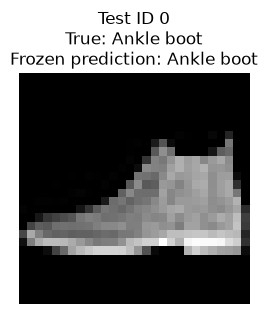

In [16]:
sample_id = 0
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(test_images[sample_id], cmap="gray", vmin=0, vmax=255)
ax.axis("off")
ax.set_title(f"Test ID {sample_id}\nTrue: {CLASS_NAMES[test_labels[sample_id]]}\nFrozen prediction: {CLASS_NAMES[selected_predictions[sample_id]]}")
plt.show()

## Takeaways

In [17]:
weak = selected_recalls.sort_values("recall").iloc[0]
gains = pd.DataFrame(deltas)
display(Markdown(
    f"1. The predeclared validation-selected model achieved **{selected.accuracy:.2%} test accuracy** "
    f"and **{selected.macro_f1:.4f} macro F1**.\n"
    f"2. Its weakest category recall was **{weak['category']}: {weak['recall']:.1%}**. "
    "Aggregate accuracy therefore does not describe every category equally.\n"
    "3. HOG's effect must be assessed within each classifier using the delta table, "
    "together with preprocessing, runtime and storage.\n"
    "4. This is a one-split benchmark comparison. Repeated seeds, wider tuning and a "
    "true catalogue-image holdout are limitations/future work.\n"
    "5. A CNN is a motivated **Phase 2 hypothesis**, not a measured result in this notebook."))

1. The predeclared validation-selected model achieved **90.91% test accuracy** and **0.9090 macro F1**.
2. Its weakest category recall was **Shirt: 73.3%**. Aggregate accuracy therefore does not describe every category equally.
3. HOG's effect must be assessed within each classifier using the delta table, together with preprocessing, runtime and storage.
4. This is a one-split benchmark comparison. Repeated seeds, wider tuning and a true catalogue-image holdout are limitations/future work.
5. A CNN is a motivated **Phase 2 hypothesis**, not a measured result in this notebook.

## Reproduction and individual review

See README for commands to reproduce training in an isolated `CLOTHING_RESULTS_ROOT`.
The default notebook examines checked-in evidence; it makes no new selection decision.
The model artifacts and raw data are excluded from Git, while split IDs, predictions,
configuration hashes, figures and recorded results are retained.

Nakul should be able to trace each module, reproduce one metric from its CSV, explain
the frozen selection and identify a failure. All five members must add real review or
implementation contributions to `docs/contributions.md` and prepare for individual viva.